# Implied volatility: inversion, shape and arbitrage

Family 20. Implied volatilities invert supplied prices. A smile fit is a model
of total variance, and passing grid diagnostics is not a proof of global
arbitrage freedom.

In [1]:
from pathlib import Path
import sys
root = Path.cwd()
if not (root / 'convexity').exists():
    root = root.parent
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from convexity.math import contracts as ct, curves as cv, pricing as pr
rng = np.random.default_rng(2000)
ref, expiry = '2026-01-01', '2027-01-01'
discount, dividend = cv.flat_curve(ref, .04), cv.flat_curve(ref, .01)
model = pr.BlackScholesModel(100., discount, dividend, .2)
plt.rcParams.update({'figure.figsize': (9, 3.5), 'figure.dpi': 110,
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': .2})
print('Interpreter:', sys.executable)

Interpreter: /home/ethan/miniconda3/envs/quant/bin/python


## Recover a supplied smile from option prices

The raw SVI curve supplies synthetic total variances at a one-year expiry.
Black inversion should recover their square roots. Normal volatility uses
different units and also permits negative forwards and strikes.

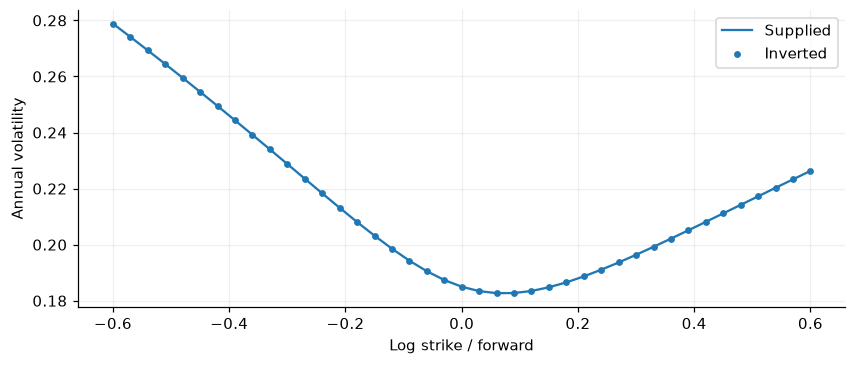

Maximum inversion error: 2.20795604022328e-13


In [2]:
from convexity.math import implied_volatility as iv
smile=iv.SVI(.02,.07,-.3,.01,.2)
k=np.linspace(-.6,.6,41);forward=100*np.exp(.03);strikes=forward*np.exp(k)
vol=np.sqrt(smile(k))
premiums=[pr.forward_option(forward,s,v,1.,discount=np.exp(-.04)) for s,v in zip(strikes,vol)]
recovered=[iv.implied_volatility(p,forward,s,1.,discount=np.exp(-.04)) for p,s in zip(premiums,strikes)]
plt.plot(k,vol,label='Supplied');plt.scatter(k,recovered,s=12,label='Inverted');plt.xlabel('Log strike / forward');plt.ylabel('Annual volatility');plt.legend();plt.show()
print('Maximum inversion error:',np.max(np.abs(vol-recovered)))

## Fit and inspect total variance

The fitter imposes positivity, wing bounds and sampled butterfly constraints.
The surface report includes every supplied expiry plus intermediate times, so a
narrow calendar-arbitrage interval cannot disappear between requested samples.

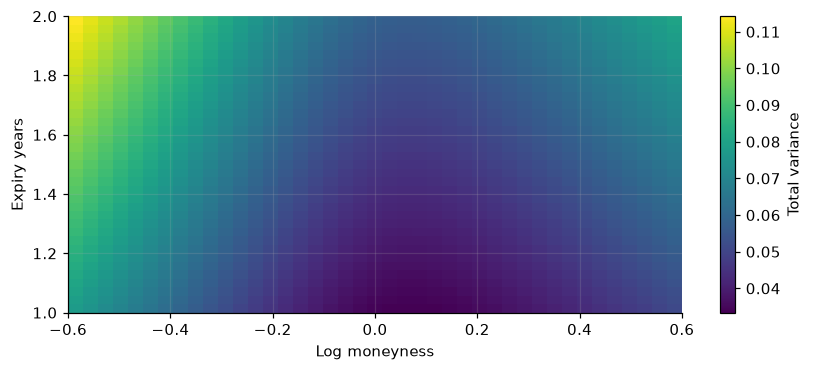

,Surface,Grid report passed
0,Smooth increasing,True
1,Narrow calendar violation,False


In [3]:
fitted=iv.SVI.fit(k,smile(k))
surface=iv.SmileSurface([1.,2.],(fitted,iv.SVI(.04,.09,-.3,.01,.2)))
times=np.linspace(1,2,35)
variance=np.array([surface.total_variance(t,k) for t in times])
plt.imshow(variance,origin='lower',aspect='auto',extent=[k.min(),k.max(),1,2]);plt.colorbar(label='Total variance');plt.xlabel('Log moneyness');plt.ylabel('Expiry years');plt.show()
low,high=iv.SVI(.01,0,0,0,.1),iv.SVI(.05,0,0,0,.1)
narrow=iv.SmileSurface([1.,1.001,1.002,2.],(low,high,low,high))
display(pd.DataFrame({'Surface':['Smooth increasing','Narrow calendar violation'],
                     'Grid report passed':[surface.diagnose(k).passed,narrow.diagnose(k,time_points=3).passed]}))

## Density and local volatility are different derivatives

The risk-neutral density is strike curvature of discounted call prices.
Dupire local volatility also depends on maturity derivatives and a consistent
surface. The constant-volatility example has an independent analytic answer.

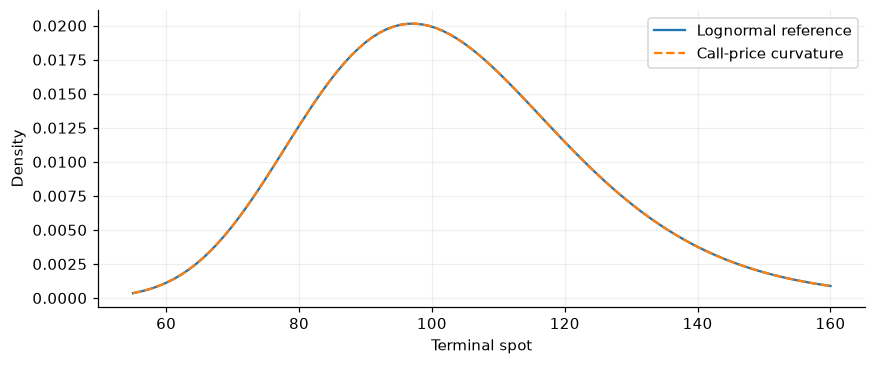

,Time,Strike,Dupire local vol
0,0.5,80,0.2
1,0.5,100,0.2
2,0.5,120,0.2
3,1.0,80,0.2
4,1.0,100,0.2
5,1.0,120,0.2
6,1.5,80,0.2
7,1.5,100,0.2
8,1.5,120,0.2


In [4]:
from scipy.stats import norm
strikes=np.linspace(55,160,100)
call=lambda strike:pr.forward_option(forward,strike,.2,1,discount=np.exp(-.04))
density=iv.risk_neutral_density(call,strikes,np.exp(-.04))
exact=norm.pdf((np.log(strikes/forward)+.5*.2**2)/.2)/(.2*strikes)
plt.plot(strikes,exact,label='Lognormal reference');plt.plot(strikes,density,'--',label='Call-price curvature');plt.xlabel('Terminal spot');plt.ylabel('Density');plt.legend();plt.show()
native=iv.black_variance_surface(ref,[expiry,'2028-01-01'],[50,100,150],np.full((3,2),.2))
display(pd.DataFrame([(t,s,iv.dupire_local_volatility(native,discount,dividend,100,t,s)) for t in [.5,1,1.5] for s in [80,100,120]],columns=['Time','Strike','Dupire local vol']))

## Scope of the evidence

These are generated-data experiments under the stated models, not market forecasts or universal model rankings. Numerical errors, backend restrictions and measure assumptions are documented in the [financial catalog](../financial_mathematics.md) and [QA record](../financial_qa.md). Automated adversarial checks live in `tests/math/finance/`.